In [ ]:
# This notebook lives in examples/: run it from the repository root so ./Data, ./Figures
# and `from utils import ...` resolve as before.
import os
if os.path.basename(os.getcwd()) == "examples":
    os.chdir("..")

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import QasmSimulator
from collections import defaultdict
import networkx as nx
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler
from qiskit.circuit import ParameterVector, Parameter
from qiskit_aer import AerSimulator
from qiskit_braket_provider import BraketProvider, BraketAwsBackend


In [10]:
service = QiskitRuntimeService(name="mcm-primitives")
# service = QiskitRuntimeService()

backends = {}
backends["qiskit_mps"] = AerSimulator(method='matrix_product_state', matrix_product_state_max_bond_dimension = 10)
# backends["ibm_fez"] = service.backend("ibm_fez", use_fractional_gates=True)
# backends["ibm_marrakesh"] = service.backend("ibm_marrakesh")
# backends["ibm_torino"] = service.backend("ibm_torino")
# backends["ibm_brisbane"] = service.backend("ibm_brisbane")
# backends["ibm_sherbrooke"] = service.backend("ibm_sherbrooke")
# backends["ibm_kyiv"] = service.backend("ibm_kyiv")
# backends["ibm_miami"] = service.backend("ibm_miami", use_fractional_gates=True)
backends["ibm_boston"] = service.backend("ibm_boston", use_fractional_gates=True)
backends["ibm_pittsburgh"] = service.backend("ibm_pittsburgh", use_fractional_gates=True)
backends["ibm_phoenix"] = service.backend("ibm_phoenix", use_fractional_gates=True)

# backends["mps"] = service.backend("simulator_mps")
# backends["qasm_simulator"] = QasmSimulator()



In [3]:
# import os 
# from iqm.qiskit_iqm import IQMProvider, transpile_to_IQM

# api_token = os.environ.get('RESONANCE_API_TOKEN')

# backends["iqm_emerald"] = IQMProvider("https://cocos.resonance.meetiqm.com/emerald", token=api_token).get_backend() 
# backends["iqm_sirius"] = IQMProvider("https://cocos.resonance.meetiqm.com/sirius", token=api_token).get_backend() 

In [4]:
service_braket = BraketProvider()
backends = {}
# backends["iqm_emerald"] = service_braket.get_backend("Emerald")
# backends["rigetti_ankaa_3"] = service_braket.get_backend("Ankaa-3")
backends["rigetti_cepheus_1_108q"] = service_braket.get_backend("Cepheus-1-108Q")

KeyboardInterrupt: 

# 1D-Chain list of qubits

List of qubits in the main 1D-Chain of IBM Eagle and Heron devices. In the main experiment, 100 qubits are used.

In [5]:
qubits_in_line = {}
# Eagle device
qubits_1D_Eagle = list(range(13,-1,-1)) + [14] + list(range(18,33)) + [36] + list(range(51,36,-1)) + [52] + list(range(56,71)) + [74] + list(range(89,74,-1)) + [90] + list(range(94,109)) + [112] + list(range(126,112,-1))

for backend in backends.keys():
    if backend[:3] == "ibm" and backend != "ibm_torino":
        qubits_in_line[backend] = qubits_1D_Eagle

# Heron device
qubits_in_line["ibm_torino"] = list(range(13,-1,-1)) + [15] + list(range(19,34)) + [37] + list(range(52,37,-1)) + [53] + list(range(57,72)) + [75] + list(range(90,75,-1)) + [91] + list(range(95,110)) + [113] + list(range(128,114,-1))
qubits_in_line["ibm_fez"] = list(range(0,16)) + [19] + list(range(35,20,-1)) + [36] + list(range(41,56)) + [59] + list(range(75,60,-1)) + [76] + list(range(81,96)) + [99] + list(range(115,100,-1)) + [116] + list(range(121,136)) + [139] + list(reversed(range(140,156)))
qubits_in_line["ibm_marrakesh"] = qubits_in_line["ibm_fez"]
qubits_in_line["ibm_pittsburgh"] = qubits_in_line["ibm_fez"]

qubits_in_line["ibm_boston"] = qubits_in_line["ibm_fez"]
qubits_in_line["ibm_miami"] = list(range(0,10)) + list(reversed(range(10,20))) + list(range(20,30)) + list(reversed(range(30,40))) + list(range(40,50)) + list(reversed(range(50,60))) + list(range(60,70)) + list(reversed(range(70,80))) + list(range(80,90)) + list(reversed(range(90,100))) + list(range(100,110)) + list(reversed(range(110,120))) 

qubits_in_line["ibm_phoenix"] = qubits_in_line["ibm_miami"]# Ankaa 2
qubits_in_line["ankaa_2"] = []
for i in range(7):
    if i%2:
        qubits_in_line["ankaa_2"]  += [i + j*7 for j in range(12)]
    else:
        qubits_in_line["ankaa_2"]  += [i + j*7 for j in reversed(range(12))]
# IQM Emerald

qubits_in_line["iqm_emerald"] = list(np.array([1,2,6,12,13,14,22,30,31,39,38,46,45,51,50,54,53,52,48,42,43,35,36,37,29,21,20,28,27,19,11,5,4,10,18,26,34,33,32,24,23,15,16,17,9,3]) - 1)
qubits_in_line["iqm_sirius"] = list(range(16))
# Rigetti Cepheus-1: 12 rows of 9 qubits labelled 0..107 on the chip, but device
# qubit 8 is not in the current calibration, so Braket reports only 107 qubits.
# qiskit-braket-provider numbers its qubits contiguously (0..106) and maps
# index -> device label through backend.qubit_labels, i.e. every device label
# above 8 is shifted down by one. The snake below is written in DEVICE labels
# and then translated, because using the raw labels as qiskit indices (a) is not
# a path in the provider coupling map, so the transpiler has to insert swaps,
# and (b) reaches device label 107, which makes Braket serialise the program as
# "qubit[108] q;" and reject the task with
# "Used 108 qubits, which is more than the device qubit count of 107".
cepheus_labels = list(reversed(range(0,8))) + list(range(9,18)) + list(reversed(range(18,27))) + list(range(27,36))
cepheus_labels += list(reversed(range(36,45))) + list(range(45,54)) + list(reversed(range(54,63))) + list(range(63,72)) + list(reversed(range(72,81)))
cepheus_labels += list(range(81,90)) + list(reversed(range(90,99))) + list(range(99,107))

if "rigetti_cepheus_1_108q" in backends:
    label_to_index = {label: i for i, label in enumerate(backends["rigetti_cepheus_1_108q"].qubit_labels)}
else:  # same mapping, hard-coded, when the backend has not been instantiated
    label_to_index = {label: (label if label < 8 else label - 1) for label in range(108)}

qubits_in_line["rigetti_cepheus_1_108q"] = [label_to_index[q] for q in cepheus_labels]

In [6]:
problems = np.load("./Data/problems_1DChain.npy", allow_pickle=True).item()

# QAOA Circuit 

In [7]:
def maxcut_qaoa_ibm(GT, layers, max_nq, qubits_in_line, fractional_gates=True):
    """
    Constructs a QAOA (Quantum Approximate Optimization Algorithm) circuit for solving the Max-Cut problem 
    on a given weighted graph using IBM quantum hardware constraints.

    Parameters:
    GT (networkx.Graph): The input weighted graph where edge weights represent the cost of a cut.
    layers (int): Number of QAOA layers (depth of the circuit).
    max_nq (int): Maximum number of qubits available for computation.
    qubits_in_line (list): A list specifying the qubit topology (linear connectivity).
    fractional_gates (bool, optional): If True, uses RZZ gates for optimization. 
                                       If False, decomposes RZZ into CX and RZ gates. 
                                       Default is True (preferred for IBM quantum processors).

    Returns:
    QuantumCircuit: A quantum circuit implementing the QAOA Max-Cut algorithm.
    """

    # Define parameter vectors for optimization angles
    betas = ParameterVector("betas", layers)  # Mixing layer rotation angles
    gammas = ParameterVector("gamma", layers)  # Phase-separating layer angles

    # Define two alternating layers for edge connections in a linear qubit topology
    layer_1 = [[qubits_in_line[i], qubits_in_line[i+1]] for i in range(0, len(qubits_in_line)-1, 2)]
    layer_2 = [[qubits_in_line[i], qubits_in_line[i+1]] for i in range(1, len(qubits_in_line)-1, 2)]
    
    # Get the number of nodes in the graph
    nodes = GT.number_of_nodes()
    
    # Find the maximum absolute edge weight in the graph for normalization
    max_weight = np.max(np.abs([GT[i][j]["weight"] for i, j in GT.edges()]))
    
    # Initialize the quantum circuit with max_nq qubits and classical bits for measurement
    qc = QuantumCircuit(max_nq, nodes)
    
    # Get a list of graph nodes
    nodes_list = list(GT.nodes)
    
    # Apply Hadamard gates to all qubits to create an equal superposition state
    qc.h(nodes_list)

    # Apply QAOA layers
    for p in range(layers):
        # Apply phase-separating unitaries using the problem Hamiltonian
        for i, j in GT.edges():
            w = GT[i][j]["weight"]  # Get edge weight
            qbits = [i, j]
            
            # Apply controlled phase shift on layer 1 edges
            if (sorted(qbits) in layer_1 or qbits in layer_1) and abs(w) > 1e-6:
                if fractional_gates:
                    # Use native RZZ gate for more efficient execution on IBM hardware
                    qc.rzz(2 * gammas[p] * GT[i][j]["weight"] / max_weight, *qbits)
                else:
                    # Decomposed version using CX and RZ gates
                    qc.cx(*qbits)
                    qc.rz(2 * gammas[p] * GT[i][j]["weight"] / max_weight, j)
                    qc.cx(*qbits)

        # Apply controlled phase shift on layer 2 edges
        for i, j in GT.edges():
            w = GT[i][j]["weight"]
            qbits = [i, j]
            
            if (sorted(qbits) in layer_2 or qbits in layer_2) and abs(w) > 1e-6:
                if fractional_gates:
                    # Use native RZZ gate if allowed
                    qc.rzz(2 * gammas[p] * GT[i][j]["weight"] / max_weight, *qbits)
                else:
                    # Decomposed implementation
                    qc.cx(*qbits)
                    qc.rz(2 * gammas[p] * GT[i][j]["weight"] / max_weight, j)
                    qc.cx(*qbits)

        # Apply mixing layer with RX rotations to all qubits
        qc.rx(-2 * betas[p], nodes_list)

    # Measure all qubits and store results in classical bits
    qc.measure(nodes_list, range(nodes))

    return qc  # Return the constructed QAOA circuit


def maxcut_qaoa_ibm_bound(GT, betas, gammas, max_nq, qubits_in_line, fractional_gates=True, isa=False):
    """
    Builds the same QAOA Max-Cut circuit as maxcut_qaoa_ibm, but with the
    angles bound to numeric values at construction time.

    For very deep circuits (p ~ 10^4-10^5, i.e. tens of millions of gates)
    the parameterized route runs out of memory: every rzz angle becomes a
    symbolic ParameterExpression object, and assign_parameters later makes a
    full extra copy of the circuit. Since the LR-QAOA schedule is known
    before the circuit is built, binding floats directly avoids all of that.

    Parameters:
    GT (networkx.Graph): The input weighted graph.
    betas (array-like): Mixing angles, one per layer.
    gammas (array-like): Phase-separating angles, one per layer.
    max_nq (int): Number of qubits of the target backend.
    qubits_in_line (list): Linear chain of physical qubits.
    fractional_gates (bool, optional): If True, uses native RZZ gates.
                                       If False, decomposes into CX and RZ.
    isa (bool, optional): If True, emits the circuit directly in the native
        basis of IBM Heron backends with fractional gates enabled
        ({rz, sx, x, rx, rzz}), so it can be submitted to the Sampler
        WITHOUT calling transpile — whose internal DAG needs roughly 10x
        the memory of the circuit itself at these depths. Hadamards are
        emitted as rz(pi/2)-sx-rz(pi/2) (equal up to a global phase), and
        a ValueError is raised if any rzz angle falls outside the hardware
        window [0, pi/2]. Requires fractional_gates=True and qubits_in_line
        to be physical qubits coupled on the device.

    Returns:
    QuantumCircuit: The bound QAOA circuit.
    """
    layers = len(betas)

    # Find the maximum absolute edge weight in the graph for normalization
    max_weight = np.max(np.abs([GT[i][j]["weight"] for i, j in GT.edges()]))

    # Classify the graph edges into the two alternating brick layers once,
    # instead of re-scanning the layer lists for every edge in every layer
    pairs_1 = {frozenset((qubits_in_line[i], qubits_in_line[i+1])) for i in range(0, len(qubits_in_line)-1, 2)}
    pairs_2 = {frozenset((qubits_in_line[i], qubits_in_line[i+1])) for i in range(1, len(qubits_in_line)-1, 2)}
    edges_1, edges_2 = [], []
    for i, j in GT.edges():
        w = GT[i][j]["weight"] / max_weight
        if abs(w) <= 1e-6:
            continue
        if frozenset((i, j)) in pairs_1:
            edges_1.append((i, j, w))
        elif frozenset((i, j)) in pairs_2:
            edges_2.append((i, j, w))
    ordered_edges = edges_1 + edges_2  # layer-1 edges first, then layer-2

    if isa:
        if not fractional_gates:
            raise ValueError("isa=True requires fractional_gates=True (native rzz/rx).")
        weights = [w for _, _, w in ordered_edges]
        angles = 2 * np.outer(np.abs(np.asarray(gammas, dtype=float)), weights)
        if np.asarray(gammas, dtype=float).min() < 0 or angles.min() < 0 or angles.max() > np.pi / 2 + 1e-12:
            raise ValueError(
                f"rzz angles span [{angles.min():.3f}, {angles.max():.3f}] rad, outside the "
                "hardware window [0, pi/2]; use isa=False and transpile instead."
            )

    nodes = GT.number_of_nodes()
    nodes_list = list(GT.nodes)

    qc = QuantumCircuit(max_nq, nodes)
    if isa:
        # h = rz(pi/2) sx rz(pi/2) up to a global phase
        qc.rz(np.pi / 2, nodes_list)
        qc.sx(nodes_list)
        qc.rz(np.pi / 2, nodes_list)
    else:
        qc.h(nodes_list)

    for p in range(layers):
        two_gamma = 2 * float(gammas[p])
        for i, j, w in ordered_edges:
            if fractional_gates:
                qc.rzz(two_gamma * w, i, j)
            else:
                qc.cx(i, j)
                qc.rz(two_gamma * w, j)
                qc.cx(i, j)
        qc.rx(-2 * float(betas[p]), nodes_list)

    qc.measure(nodes_list, range(nodes))

    return qc


def repeat_subgraph(G, qubits_line):
    """
    Repeats a given subgraph structure multiple times across a list of qubits.

    Parameters:
    G (networkx.Graph): The base subgraph to be repeated.
    qubits_line (list): A list of qubit indices where the repeated graph structure will be mapped.

    Returns:
    networkx.Graph: A new graph GT with the repeated subgraph structure.
    """

    n_qubits = G.number_of_nodes()  # Number of nodes in the base subgraph
    n_reps = len(qubits_line) // n_qubits  # Determine how many times the subgraph is repeated

    GT = nx.Graph()  # Create an empty graph
    GT.add_nodes_from(qubits_line[:n_reps * n_qubits])  # Add nodes to GT based on qubits_line

    # Iterate over repetitions and copy edges with weights
    for rep in range(n_reps):
        for i, j in G.edges:
            w = G[i][j]["weight"]  # Extract edge weight
            # Map original nodes to repeated positions and add weighted edges
            GT.add_weighted_edges_from([[qubits_line[i + rep * n_qubits], qubits_line[j + rep * n_qubits], w]])

    return GT  # Return the expanded graph with repeated subgraphs

# Objective Function

In [8]:
def cost_maxcut(bitstring, weights):
    """
    Computes the cost of a given bitstring solution for the Max-Cut problem.

    Parameters:
    bitstring (str): A binary string representing a partition of the graph nodes (e.g., "1010").
    weights (dict): A dictionary where keys are edge tuples (i, j) and values are edge weights.

    Returns:
    float: The computed cost of the Max-Cut solution.
    """
    cost = 0  # Initialize the cost
    
    # Iterate through all edges in the graph
    for i, j in weights.keys():
        # Check if the nodes i and j are in different partitions (cut condition)
        if bitstring[i] + bitstring[j] in ["10", "01"]:
            cost += weights[i, j]  # Add the edge weight to the cost

    return cost  # Return the total cut cost


def objective_MaxCut(samples_dict, G, optimal):
    """
    Evaluates the performance of a quantum algorithm for the Max-Cut problem.

    Parameters:
    samples_dict (dict): A dictionary where keys are bitstrings (binary solutions), 
                         and values are their occurrence counts.
    G (networkx.Graph): The input weighted graph where edges represent cut costs.
    optimal (str): The optimal bitstring solution found by classical solvers (e.g., CPLEX).

    Returns:
    dict: A dictionary containing:
        - "results": A numpy array with computed cost, normalized cost ratio, and counts.
        - "G": The input graph G.
        - "weights": The edge weights extracted from G.
        - "max_cut": The cost of the optimal Max-Cut solution.
        - "r": The expected approximation ratio.
        - "probability": The probability of sampling the optimal solution.
    """

    # Extract weights from the graph's edges
    weights = {(i, j): (G[i][j]["weight"] if len(G[i][j]) != 0 else 1) for i, j in G.edges}
    
    # Compute the cost of the optimal Max-Cut solution
    max_cost = cost_maxcut(optimal, weights)

    results = []  # Stores results in the form [cost, ratio, counts]
    probability = 0  # Tracks probability of sampling the optimal solution

    # Iterate through all sampled bitstrings
    for bitstring, counts in samples_dict.items():
        cost = cost_maxcut(bitstring, weights)  # Compute cost of the given bitstring
        r = cost / max_cost  # Compute the cost ratio relative to the optimal solution
        results.append([cost, r, counts])  # Store results
        
        # If this bitstring matches the optimal cost, update probability
        if abs(cost - max_cost) < 1e-6:
            probability += counts
        
        # Check if a better-than-optimal solution appears (sanity check)
        if cost > max_cost:
            print(f"There is a better cost than that of CPLEX: {cost - max_cost}")

    # Convert results to a NumPy array for easy computation
    results = np.array(results)

    # Total number of shots (total sampled solutions)
    shots = np.sum(results[:, 2])

    # Compute the expected approximation ratio: (weighted sum of costs) / (shots * max_cost)
    rT = np.sum(results[:, 0] * results[:, 2]) / (shots * max_cost)

    # Normalize the probability of sampling the optimal solution
    probability /= shots

    # Return results in a structured dictionary
    return {
        "results": np.array(results),
        "G": G,
        "weights": weights,
        "max_cut": max_cost,
        "r": rT,
        "probability": probability
    }

def mitigate(samples_dict, G, random=False):
    """
    Applies error mitigation by flipping individual bits in sampled solutions 
    to find better Max-Cut solutions.

    Parameters:
    samples_dict (dict): A dictionary where keys are bitstrings (binary solutions), 
                         and values are their occurrence counts.
    G (networkx.Graph): The input weighted graph where edges represent cut costs.
    random (bool, optional): If True, randomizes the order in which qubits are flipped.
                             Default is False (systematic flipping).

    Returns:
    dict: A dictionary of improved bitstring samples with their updated counts.
    """

    # Define a mapping to flip bits ('0' -> '1', '1' -> '0')
    change = {"0": "1", "1": "0"}

    # Get the number of nodes (qubits)
    nq = G.number_of_nodes()

    # Extract weights from the graph's edges
    weights = {(i, j): (G[i][j]["weight"] if len(G[i][j]) != 0 else 1) for i, j in G.edges}

    # Dictionary to store new (improved) samples
    new_samples = defaultdict(int)

    # Iterate over all bitstring samples
    for bitstring, counts in samples_dict.items():
        for _ in range(counts):  # Process each occurrence of the bitstring separately
            best_string = bitstring  # Initialize the best solution as the current one
            best_cost = cost_maxcut(bitstring, weights)  # Compute its cost
            
            # Create an ordered list of qubits (nodes) to consider flipping
            list_qubits = np.arange(nq)
            
            # If random flipping is enabled, shuffle the qubit order
            if random:
                np.random.shuffle(list_qubits)

            # Try flipping each qubit and check if the cost improves
            for qi in list_qubits:
                # Flip the bit at position qi
                new_string = "".join((change[i] if n == qi else i) for n, i in enumerate(best_string))
                new_cost = cost_maxcut(new_string, weights)

                # If the new configuration gives a better cost, update the best solution
                if new_cost > best_cost:
                    best_string = new_string
                    best_cost = new_cost
            
            # Store the improved bitstring in the new_samples dictionary
            new_samples[best_string] += 1

    return new_samples  # Return the mitigated samples

def random_samples(num_samples, n_qubits):
    """
    Generates random bitstring samples for a given number of qubits.

    Parameters:
    num_samples (int): The number of random bitstrings to generate.
    n_qubits (int): The number of qubits (length of each bitstring).

    Returns:
    dict: A dictionary where keys are randomly generated bitstrings 
          and values are their occurrence counts.
    """
    
    random_samples = defaultdict(int)  # Dictionary to store bitstrings and their counts

    # Generate random bitstrings and count their occurrences
    for _ in range(num_samples):
        bitstring = "".join(str(i) for i in np.random.choice([0, 1], n_qubits))  # Generate a random bitstring
        random_samples[bitstring] += 1  # Increment count for the generated bitstring

    return random_samples  # Return the dictionary of samples


# 1) IBM Eagle and Heron: Prepare the experiments

In [13]:
# Select the backend for quantum computation
# Uncomment the desired backend or set the active one
# backend_name = "ibm_brisbane"
# backend_name = "ibm_sherbrooke"
# backend_name = "ibm_kyiv"
# backend_name = "ibm_nazca"
# backend_name = "ibm_osaka"
# backend_name = "ibm_kyoto"
# backend_name = "ibm_torino"
# backend_name = "ibm_fez"  # Active backend
# backend_name = "ibm_marrakesh"
# backend_name = "ibm_strasbourg"
# backend_name = "ibm_brussels"
# backend_name = "ankaa_2"
# backend_name = "qasm_simulator"  # Classical simulator option
# backend_name = "iqm_emerald"
# backend_name = "ibm_boston"
# backend_name = "qiskit_mps"  # Using the matrix product state simulator
# backend_name = "iqm_sirius"
# backend_name = "rigetti_cepheus_1_108q"
# backend_name = "ibm_miami"
# backend_name = "ibm_boston"
# backend_name = "ibm_pittsburgh"
backend_name = "ibm_phoenix"

results = {}  # Dictionary to store experiment results

# ---------------------- Loading Problem Information ----------------------

nq = 120  # Number of qubits (size of the problem)

# Define qubit mappings for different backends
qubits_in_line["qasm_simulator"] = range(nq)  # Simulator uses a linear qubit range
qubits_in_line["qiskit_mps"] = range(nq)  # Simulator uses a linear qubit range

# qubits_in_line[backend_name] = range(nq)
# Load the problem graph
results["G"] = problems["G"][nq]  

# Repeat subgraph structure to match the qubit layout of the chosen backend
results["GT"] = repeat_subgraph(results["G"], qubits_in_line[backend_name])

# Select the graph to use: 
# If using a real quantum backend, use the transformed graph (GT), 
# otherwise use the original problem graph (G) for the simulator
GT = results["GT"] if backend_name != "qasm_simulator" else results["G"]

# Load optimal solutions for the given problem size
sols = problems["sol"][nq]  

# Get the list of qubits assigned for the selected backend
qubits_line = qubits_in_line[backend_name]

# Get the maximum number of qubits available on the backend
max_nq = backends[backend_name].num_qubits  
# max_nq = nq + 1

# ---------------------- QAOA Configuration ----------------------

# Define the number of QAOA layers
# ps = [3, 4, 5, 6, 7, 8, 9, 10, 13, 15, 20, 25, 30, 40, 50, 75, 100]
# ps = [2]
ps = [100_000]  # Set a single large QAOA depth for testing

# Define delta values for parameter scaling
# deltas = np.linspace(0.5, 1.5, 10)  # Generate 10 values between 0.5 and 1.5
# deltas = [1.0]  # Set a single delta value for testing
deltas = [0.75]
# Store key experiment parameters in results
results["optimal"] = sols  
results["nq"] = nq  
results["ps"] = ps  
results["Deltas"] = deltas  

# ---------------------- Circuit Building & Compilation ----------------------
# For very deep circuits (large p) the old pipeline — parameterized build,
# transpile(optimization_level=1), then assign_parameters — keeps three full
# copies of a multi-million-gate circuit alive, one of them with a symbolic
# ParameterExpression per gate, and the transpiler DAG alone needs ~10x the
# memory of the circuit. Instead, bind the linear-ramp angles while building
# and, when the backend exposes fractional gates (rzz/rx native, as on
# ibm_boston/ibm_fez/ibm_miami with use_fractional_gates=True), emit the
# circuit directly in the native basis so transpile is skipped entirely.
# If the rzz angles fall outside the hardware window [0, pi/2] (e.g. for
# delta > pi/4), the builder raises and we fall back to a level-0 transpile.
import gc

circuits = []  # Store final circuits with bound parameters

for delta in deltas:
    print(f"Delta: -------  {round(delta,2)} ----------- ")  # Display current delta value
    
    for p in ps:
        print(f"Layer: -------  {p} ----------- ")  # Display current layer
        
        # Compute beta and gamma parameters for QAOA (linear ramp)
        betas = np.arange(1, p+1)[::-1] * delta/p  # Reverse sequence for betas
        gammas = np.arange(1, p+1) * delta/p  # Forward sequence for gammas
        
        try:
            # Build directly in the fractional-gate native basis: no transpile needed
            backend_circ = maxcut_qaoa_ibm_bound(GT, betas, gammas, max_nq, qubits_line,
                                                 fractional_gates=True, isa=True)
            print(f"Built directly in native basis with {backend_circ.count_ops()} gates.")
            # initial_layout keeps the qubits the circuit was built on: the circuit
            # already uses physical indices, and letting the transpiler re-pick a
            # layout can pull in the highest index (device qubit 107 on Cepheus),
            # which Braket rejects as a 108-qubit program.
            backend_circ = transpile(backend_circ, backend=backends[backend_name], optimization_level=0,
                                     initial_layout=list(range(max_nq)),)
        except ValueError as err:
            print(f"Direct ISA build not possible ({err}); falling back to transpile.")
            circ_maxcut = maxcut_qaoa_ibm_bound(GT, betas, gammas, max_nq, qubits_line,
                                                fractional_gates=True)
            backend_circ = transpile(circ_maxcut, backend=backends[backend_name], optimization_level=0,
                                     initial_layout=list(range(max_nq)))
            del circ_maxcut
            gc.collect()
        
        circuits.append(backend_circ)
        print(f"{backend_circ.count_ops()}")


Delta: -------  0.75 ----------- 
Layer: -------  100000 ----------- 
Built directly in native basis with OrderedDict([('rx', 12000000), ('rzz', 11900000), ('rz', 240), ('sx', 120), ('measure', 120)]) gates.


KeyboardInterrupt: 

# 2) IBM Eagle and Heron: Run the experiments

In [10]:
shots = 1000  # Number of measurement shots per circuit execution
extra = f""  # Additional identifier for file naming (indicating 10,000 QAOA layers)
# extra = ""  # Uncomment this line if no extra identifier is needed
results["shots"] = shots  

# Check if using a real quantum backend (not the classical simulator)
if backend_name not in ["qasm_simulator", "qiskit_mps"]:
    if backend_name in ["iqm_sirius", "iqm_emerald", "rigetti_cepheus_1_108q"]:
        submit_job = backends[backend_name].run(circuits, shots=results["shots"]) 
    else:
        # Initialize a sampler for running the circuits on a real quantum device
        sampler = Sampler(mode=backends[backend_name])
        # Submit the circuits for execution with the specified number of shots
        submit_job = sampler.run(circuits, shots=shots)

    # Store the job ID to track or retrieve results later
    results["id"] = submit_job.job_id()  
    
    # Alternative way to submit the job directly to the backend
    # submit_job = backends[backend_name].run(circuits, shots=shots)
    # results["id"] = submit_job.job_id()  # Save job ID for retrieval

else:
    # If using the qasm_simulator (classical simulator), execute the circuits directly
    dict_results = backends[backend_name].run(circuits, shots=shots).result().get_counts()
    
    # Process the results:
    # - Reverse bitstrings (to match standard qubit ordering)
    # - Organize results into a nested dictionary: {delta -> {p -> {bitstring -> counts}}}
    results["samples"] = {
        delta: {
            p: {k[::-1]: v for k, v in dict_results[i + nd * len(ps)].items()} 
            for i, p in enumerate(results["ps"])
        } 
        for nd, delta in enumerate(results["Deltas"])
    }

# Save results as a NumPy binary file for further analysis
import os
os.makedirs(f"./Data/{backend_name}", exist_ok=True)  # Create directory if it doesn't exist
np.save(f"./Data/{backend_name}/{nq}_1D{extra}.npy", results)  


# Retrieve the experimental information

In [11]:
backend_name = "ibm_phoenix"  # Define the IBM backend used for execution

# Specify additional identifier for file naming:
extra = ""  # No extra identifier

nq = 100  # Number of qubits

# Load the previously saved results from a NumPy binary file
results = np.load(f"./Data/{backend_name}/{nq}_1D{extra}.npy", allow_pickle=True).item()

braket_counts = None  # filled in below for AWS Braket backends

# If using a real quantum device, retrieve job results from IBM Quantum service
if backend_name not in ["qasm_simulator", "qiskit_mps"]:
    # Fetch the job results using its stored job ID
    if backend_name in ["iqm_sirius", "iqm_emerald", "rigetti_cepheus_1_108q"]:
        if type(backends[backend_name]) is BraketAwsBackend:
            # Read the counts straight from the Braket SDK instead of going through
            # BraketQuantumTask.result(), which breaks in two ways:
            #   * it treats every single task ARN as a program set, so retrieving a
            #     1-circuit submission raises
            #     TypeError: 'GateModelQuantumTaskResult' object is not iterable;
            #   * it assumes every program of a set succeeded, so a partially failed
            #     set raises AttributeError: 'ProgramSetExecutableFailure' object has
            #     no attribute 'measurements'.
            # Individual programs fail while the task as a whole reports COMPLETED,
            # e.g. when the compiled circuit passes Rigetti's 20,000-gate limit
            # (the 100-qubit chain does so from p = 3 on).
            from braket.aws import AwsQuantumTask

            task = AwsQuantumTask(arn=results["id"])
            task_result = task.result()
            program_results = (
                [task_result]  # plain single-circuit task
                if hasattr(task_result, "measurement_counts")
                else [entry[0] for entry in task_result]  # one entry per program
            )

            # Circuits are submitted delta-major, p-minor (see the circuit-building cell)
            submitted = [(delta, p) for delta in results["Deltas"] for p in results["ps"]]
            braket_counts = {}
            for (delta, p), program_result in zip(submitted, program_results):
                failure = getattr(program_result, "failureMetadata", None)
                if failure is not None:
                    print(f"delta = {delta}, p = {p} failed on the device and is skipped:")
                    print(f"    {failure.failureReason}")
                    continue
                # Braket orders the bits by measurement order, i.e. bit i belongs to
                # the i-th node of GT, which is exactly what the postprocessing cell
                # expects — so, unlike the IBM counts, these must NOT be reversed.
                counts = getattr(program_result, "measurement_counts", None)
                braket_counts[(delta, p)] = dict(counts if counts is not None else program_result.counts)

            # Keep only the depths that actually came back, so the plots don't KeyError
            if len(braket_counts) < len(submitted):
                results["ps_submitted"] = list(results["ps"])
                results["ps"] = [p for p in results["ps"]
                                 if any((delta, p) in braket_counts for delta in results["Deltas"])]

            metadata = task.metadata()
            created, ended = metadata.get("createdAt"), metadata.get("endedAt")
            results["runtime"] = {
                "time_taken_seconds": (ended - created).total_seconds() if created and ended else None
            }
        else:
            jobs = backends[backend_name].retrieve_job(job_id=results["id"]).result()
            dict_results = jobs.get_counts()

            # Wall-clock runtime reported by the provider, when available
            results["runtime"] = {"time_taken_seconds": getattr(jobs, "time_taken", None)}
    else:
        job_obj = service.job(job_id=results["id"])
        job = job_obj.result()

        # Extract bitstring measurement results from all circuits in the job
        dict_results = [job[i].data.c.get_counts() for i in range(len(job))]

        # ---------------- Runtime information for the job ----------------
        runtime = {}
        # QPU seconds consumed by the job (what IBM bills for)
        runtime["usage_seconds"] = job_obj.usage()
        # Job timestamps (ISO 8601): created, running, finished
        runtime["timestamps"] = job_obj.metrics().get("timestamps", {})
        # Per-circuit execution spans: actual start/stop of each pub on the QPU
        try:
            spans = job.metadata["execution"]["execution_spans"]
            runtime["execution_spans"] = [
                {"start": s.start, "stop": s.stop, "duration_seconds": s.duration}
                for s in spans
            ]
        except (KeyError, AttributeError, TypeError):
            pass
        results["runtime"] = runtime
        print(f"QPU usage: {runtime['usage_seconds']} s | timestamps: {runtime['timestamps']}")

    # Process and store results:
    # - Reverse bitstrings (`k[::-1]`) to match standard qubit ordering.
    # - Organize results into a nested dictionary: {delta -> {p -> {bitstring -> counts}}}.
    if braket_counts is not None:
        results["samples"] = {
            delta: {p: braket_counts[(delta, p)] for p in results["ps"] if (delta, p) in braket_counts}
            for delta in results["Deltas"]
        }
    else:
        results["samples"] = {
            delta: {
                p: {k[::-1]: v for k, v in dict_results[i + nd * len(results["ps"])].items()}
                for i, p in enumerate(results["ps"])
            }
            for nd, delta in enumerate(results["Deltas"])
        }

np.save(f"./Data/{backend_name}/{nq}_1D{extra}.npy", results)  



QPU usage: 4 s | timestamps: {'created': '2026-09-02T13:36:25.297119Z', 'finished': '2026-09-02T13:41:41.731742Z', 'running': '2026-09-02T13:41:16.311712Z'}


# Postprocessing the samples

In [12]:
# Extract the number of nodes (qubits) in the original and repeated graph
nq = results["G"].number_of_nodes()  # Number of qubits in the original problem graph
nq_total = results["GT"].number_of_nodes()  # Number of qubits in the repeated subgraph
sections = nq_total // nq  # Number of repeated sections in the larger subgraph

# Dictionaries to store post-processing results
postprocessing = {}
# postprocessing_mitig = {}

# Iterate over different values of delta (hyperparameter for QAOA)
for delta in results["samples"]:
    postprocessing[delta] = {}
    # postprocessing_mitig[delta] = {}

    # Iterate over different QAOA layer depths (p)
    for p in results["samples"][delta]:
        print(f"----------- p = {p} -------------")
        postprocessing[delta][p] = {}
        # postprocessing_mitig[delta][p] = {}

        # Iterate over each section of the repeated subgraph
        for sec in range(sections):
            samples_sec = defaultdict(int)

            # Extract samples corresponding to the current section
            for k, v in results["samples"][delta][p].items():
                samples_sec[k[sec * nq : (sec + 1) * nq]] += v

            # Compute objective function for the MaxCut problem
            postprocessing[delta][p][sec] = objective_MaxCut(samples_sec, results["G"], results["optimal"][0])

            # Apply error mitigation (local search improvement)
            # new_samples = mitigate(samples_sec, results["G"], random=False)

            # Compute the objective function for mitigated results
            # postprocessing_mitig[delta][p][sec] = objective_MaxCut(new_samples, results["G"], results["optimal"][0])

# Store the post-processed and mitigated results
results["postprocessing"] = postprocessing
# results["postprocessing_mitig"] = postprocessing_mitig

# Generate random bitstring samples for comparison
rand_samples = random_samples(10_000, nq)

# Compute the objective function for random sampling (baseline performance)
results["random"] = objective_MaxCut(rand_samples, results["G"], results["optimal"][0])

# Apply error mitigation to random samples and evaluate performance
# results["random_mitig"] = objective_MaxCut(mitigate(rand_samples, results["G"], random=False), results["G"], results["optimal"][0])

# Save the updated results dictionary
np.save(f"./Data/{backend_name}/{nq}_1D{extra}.npy", results)


----------- p = 3 -------------
----------- p = 4 -------------
----------- p = 5 -------------
----------- p = 6 -------------
----------- p = 7 -------------
----------- p = 8 -------------
----------- p = 9 -------------
----------- p = 10 -------------
----------- p = 13 -------------
----------- p = 15 -------------
----------- p = 20 -------------
----------- p = 25 -------------
----------- p = 30 -------------
----------- p = 40 -------------
----------- p = 50 -------------
----------- p = 75 -------------
----------- p = 100 -------------


In [68]:
results["postprocessing"][1.0][2][0]["r"]

np.float64(0.48946307692307656)

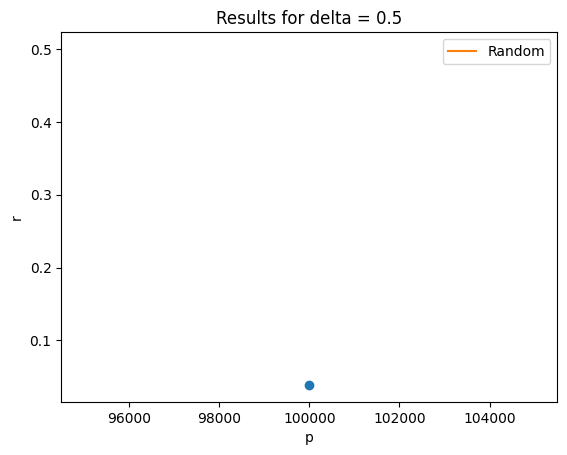

In [29]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
for i in range(1):
    ax.plot(results["ps"], [results["postprocessing"][delta][p][i]["r"] for p in results["ps"]], marker="o", linewidth=0)
ax.plot(results["ps"], [results["random"]["r"] for p in results["ps"]], label="Random")
ax.set_xlabel("p")
ax.set_ylabel("r")
ax.set_title(f"Results for delta = {delta}")
ax.legend()
plt.show()

# AWS experiments

In [1]:
from braket.aws import AwsDevice, AwsQuantumTask
from braket.devices import Devices, LocalSimulator
from braket.circuits import Circuit, Measure

In [2]:
backends = {}
backends["iqm_garnet"] = AwsDevice(Devices.IQM.Garnet)
# backends["rigetti_ankaa_3"] = AwsDevice(Devices.Rigetti.Ankaa3)
backends["rigetti_cepheus_1_108q"] = AwsDevice(Devices.Rigetti.Cepheus1108Q)
backends["local_simulator"] = LocalSimulator()



In [3]:
# G = backends["rigetti_ankaa_3"].topology_graph
# path = [0]
# while True:
#     neighbor_qubits = list(G[path[-1]].keys())
#     suma = 0
#     for q in neighbor_qubits:
#         if q not in path and q not in [35,55]:
#             path.append(q)
#             break
#         else:
#             suma += 1
#     if suma == len(neighbor_qubits):
#         break
    
# qubits_in_line = {"rigetti_ankaa_3":path, "iqm_garnet":[2, 3, 0, 1, 4, 5, 6, 11, 10, 9, 8, 7, 12, 13, 14, 15, 19, 18, 17]}

In [33]:
def qaoa_maxcut_aws_sorted(gammas, betas, G, qubits_in_line):
    nq = G.number_of_nodes()
    p = len(gammas) 
    nodes = G.nodes()
    weights = [G[i][j]["weight"] for i,j in G.edges()]
    max_weight = max(weights)
    qc = Circuit()
    qc.h(nodes)
    layers = [[(qubits_in_line[i],qubits_in_line[i+1]) for i in range(j, nq-1, 2)] for j in range(2)]
    for pi in range(p):
        for layer in layers:
            for i, j in G.edges():
                if (i,j) in layer or (j,i) in layer:
                    qc.cnot(i, j)
                    qc.rz(j, 2 * gammas[pi] * G[i][j]["weight"]/max_weight)
                    qc.cnot(i, j)
        qc.rx(nodes, -2 * betas[pi])
    
    for node in nodes:
        qc.measure(node)
    return qc

In [34]:
import numpy as np
import networkx as nx
problems = np.load("./Data/problems_1DChain.npy", allow_pickle=True).item()

In [57]:
# Select the backend for quantum computation
# Uncomment the desired backend or set the active one
# backend_name = "rigetti_ankaa_3"  # Active backend
# backend_name = "iqm_garnet"  # Active backend
# backend_name = "local_simulator"
backend_name = "rigetti_cepheus_1_108q"
extra = "braket"
results = {}  # Dictionary to store experiment results

# ---------------------- Loading Problem Information ----------------------

nq = 19  # Number of qubits (size of the problem)

# Load the problem graph
results["G"] = problems["G"][nq]  

qubits_in_line["local_simulator"] = [3,5,4,2,1,6,7]
if extra == "single":   
    qubits_used = qubits_in_line[backend_name][:nq]
else: 
    qubits_used = qubits_in_line[backend_name]

# Repeat subgraph structure to match the qubit layout of the chosen backend
results["GT"] = repeat_subgraph(results["G"], qubits_used)

# Select the graph to use: 
# If using a real quantum backend, use the transformed graph (GT), 
# otherwise use the original problem graph (G) for the simulator
GT = results["GT"] if backend_name != "qasm_simulator" else results["G"]

# Load optimal solutions for the given problem size
sols = problems["sol"][nq]  

# Get the maximum number of qubits used on the backend
max_nq = len(qubits_used)

# ---------------------- QAOA Configuration ----------------------

# Define the number of QAOA layers
# ps = [3, 4, 5, 6, 7, 8, 9, 10, 13, 15, 20, 25, 30, 40, 50, 75, 100] 
ps = [3, 4, 5]  
 
# ps = [3]  

# ps = [10_000]  # Set a single large QAOA depth for testing

# Define delta values for parameter scaling
# deltas = np.linspace(0.5, 1.5, 10)  # Generate 10 values between 0.5 and 1.5
deltas = [1]  # Set a single delta value for testing

# Store key experiment parameters in results
results["optimal"] = sols  
results["nq"] = nq  
results["ps"] = ps  
results["Deltas"] = deltas  

# ---------------------- Circuit Compilation ----------------------

circuits = []
# Iterate over different QAOA layers
for delta in deltas:
    print(f"Delta: -------  {round(delta,2)} ----------- ")  # Display current delta value
    for p in ps:
        print(f"Layer: -------  {p} ----------- ")  # Display current layer
        
        betas = list(np.arange(1, p+1)[::-1] * delta/p)  # Reverse sequence for betas
        gammas = list(np.arange(1, p+1) * delta/p)  # Forward sequence for gammas
        # Generate the QAOA circuit for MaxCut problem
        circ_maxcut = qaoa_maxcut_aws_sorted(gammas, betas, GT, qubits_used)
        # Store the transpiled circuit  
        circuits.append(circ_maxcut) 
         


Delta: -------  1 ----------- 
Layer: -------  3 ----------- 
Layer: -------  4 ----------- 
Layer: -------  5 ----------- 


In [58]:
# sorted_qubits = np.argsort(list(results["GT"].nodes()))
# qubits_dict = {j:i for i,j in enumerate(sorted_qubits)}
# samples = backends["local_simulator"].run(circuits[-1], shots=100).result().measurement_counts
# print({"".join(k[qubits_dict[ii]] for ii in results["GT"].nodes()):v for k, v in dict(samples).items()})

The p = 100 and Nq = 10 produced an error "Compilation timed out or produced an error. Please reach out to AWS Customer Support for support."

In [59]:
shots = 1_000

results["shots"] = shots
ids = {}
for i in range(len(circuits)):
# run circuit
    task = backends[backend_name].run(circuits[i], shots=shots, disable_qubit_rewiring=True)
    ids[ps[i]] = task.id
    # get id and status of submitted quantum task

    status = task.state()
    # print('ID of quantum task:', iqm_task_id)
    print('Status of quantum task:', status)
results["ids"] = ids
np.save(f"./Data/{backend_name}/{nq}_1D{extra}.npy", results)

Status of quantum task: QUEUED
Status of quantum task: QUEUED
Status of quantum task: QUEUED


In [60]:
# backend_name = "iqm_garnet"
# backend_name = "rigetti_ankaa_3"
backend_name = "rigetti_cepheus_1_108q"
extra = "braket"
nq = 19
results = np.load(f"./Data/{backend_name}/{nq}_1D{extra}.npy", allow_pickle=True).item()
results["ps"] = results["ps"]
# results["ps"] = [3,4,5]
dict_results = [AwsQuantumTask(arn=results["ids"][p]).result().measurement_counts for p in results["ps"]]
sort_bitstrings = results["GT"].nodes()

qubits_dict = {i:i for i,j in enumerate(results["GT"].nodes())}
results["samples"] = {delta:{p:{"".join(k[qubits_dict[ii]] for ii,jj in enumerate(results["GT"].nodes())):v for k, v in dict_results[i+nd*len(results["ps"])].items()} for i, p in enumerate(results["ps"])} for nd, delta in enumerate(results["Deltas"])}

In [61]:
from collections import defaultdict
nq = results["G"].number_of_nodes()
nq_total = results["GT"].number_of_nodes()
sections = nq_total // nq
results["sections"]  = sections
postprocessing = {}
# postprocessing_mitig = {}
for delta in results["samples"]:
    postprocessing[delta] = {}
    # postprocessing_mitig[delta] = {}
    for p in results["samples"][delta]:
        print(f"----------- p = {p} -------------")
        postprocessing[delta][p] = {}
        # postprocessing_mitig[delta][p] = {}
        for sec in range(sections):
            samples_sec = defaultdict(int)
            for k, v in results["samples"][delta][p].items():
                samples_sec[k[sec*nq:(sec+1)*nq]] += v
            postprocessing[delta][p][sec] = objective_MaxCut(samples_sec, results["G"], results["optimal"][0])
            # new_samples = mitigate(samples_sec, results["G"], random=False)
            # postprocessing_mitig[delta][p][sec] = objective_MaxCut(new_samples, results["G"], results["optimal"][0])
results["postprocessing"] = postprocessing
# results["postprocessing_mitig"] = postprocessing_mitig

rand_samples = random_samples(10000, nq)
results["random"] = objective_MaxCut(rand_samples, results["G"], results["optimal"][0])
# results["random_mitig"] = objective_MaxCut(mitigate(rand_samples, results["G"], random=False), results["G"], results["optimal"][0])

np.save(f"./Data/{backend_name}/{nq}_1D{extra}.npy", results)

----------- p = 3 -------------
----------- p = 4 -------------
----------- p = 5 -------------


Text(0.5, 0, 'p')

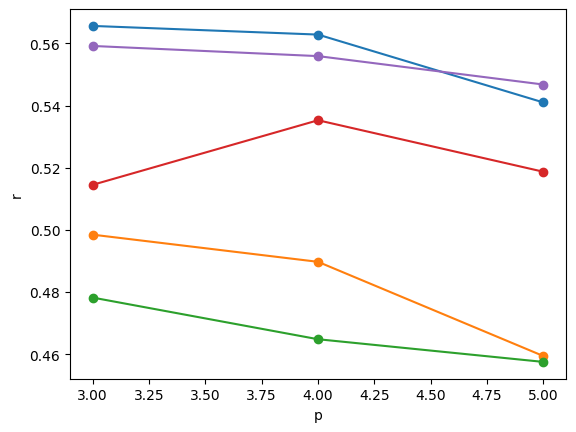

In [62]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
delta = results["Deltas"][0]
for i in range(results["sections"]):
    ax.plot(results["postprocessing"][delta].keys(), [results["postprocessing"][delta][p][i]["r"] for p in postprocessing[delta].keys()], marker="o")
ax.set_ylabel("r")

ax.set_xlabel("p")

In [49]:
# backend_name = "iqm_garnet"
backend_name = "rigetti_cepheus_1_108q"
extra = "braket"
nq = 100
results = np.load(f"./Data/{backend_name}/{nq}_1D{extra}.npy", allow_pickle=True).item()
task_load = AwsQuantumTask(arn=results["ids"][3])
metadata = task_load.metadata()
rigetti_results = task_load.result()
print(
        "The compiled circuit is:\n",
        rigetti_results.additional_metadata.rigettiMetadata.compiledProgram,
    )

circ_str = rigetti_results.additional_metadata.rigettiMetadata.compiledProgram
circ_str.split("\n")[-100:]
# circ_str.count("ISWAP")

The compiled circuit is:
 PRAGMA INITIAL_REWIRING "NAIVE"
DECLARE ro BIT[100]
PRAGMA PRESERVE_BLOCK
RZ(1.5707963267948966) 0
RZ(1.5707963267948966) 1
RZ(1.5707963267948966) 2
RZ(1.5707963267948966) 3
RZ(1.5707963267948966) 4
RZ(1.5707963267948966) 5
RZ(1.5707963267948966) 6
RZ(1.5707963267948966) 7
RZ(1.5707963267948966) 9
RZ(1.5707963267948966) 10
RZ(1.5707963267948966) 11
RZ(1.5707963267948966) 12
RZ(1.5707963267948966) 13
RZ(1.5707963267948966) 14
RZ(1.5707963267948966) 15
RZ(1.5707963267948966) 16
RZ(1.5707963267948966) 17
RZ(1.5707963267948966) 18
RZ(1.5707963267948966) 19
RZ(1.5707963267948966) 20
RZ(1.5707963267948966) 21
RZ(1.5707963267948966) 22
RZ(1.5707963267948966) 23
RZ(1.5707963267948966) 24
RZ(1.5707963267948966) 25
RZ(1.5707963267948966) 26
RZ(1.5707963267948966) 27
RZ(1.5707963267948966) 28
RZ(1.5707963267948966) 29
RZ(1.5707963267948966) 30
RZ(1.5707963267948966) 31
RZ(1.5707963267948966) 32
RZ(1.5707963267948966) 33
RZ(1.5707963267948966) 34
RZ(1.5707963267948966) 35

['MEASURE 7 ro[0]',
 'MEASURE 100 ro[99]',
 'MEASURE 6 ro[1]',
 'MEASURE 4 ro[3]',
 'MEASURE 2 ro[5]',
 'MEASURE 0 ro[7]',
 'MEASURE 10 ro[9]',
 'MEASURE 12 ro[11]',
 'MEASURE 14 ro[13]',
 'MEASURE 16 ro[15]',
 'MEASURE 26 ro[17]',
 'MEASURE 24 ro[19]',
 'MEASURE 22 ro[21]',
 'MEASURE 20 ro[23]',
 'MEASURE 18 ro[25]',
 'MEASURE 28 ro[27]',
 'MEASURE 30 ro[29]',
 'MEASURE 32 ro[31]',
 'MEASURE 34 ro[33]',
 'MEASURE 44 ro[35]',
 'MEASURE 42 ro[37]',
 'MEASURE 40 ro[39]',
 'MEASURE 38 ro[41]',
 'MEASURE 36 ro[43]',
 'MEASURE 46 ro[45]',
 'MEASURE 48 ro[47]',
 'MEASURE 50 ro[49]',
 'MEASURE 52 ro[51]',
 'MEASURE 62 ro[53]',
 'MEASURE 60 ro[55]',
 'MEASURE 58 ro[57]',
 'MEASURE 56 ro[59]',
 'MEASURE 54 ro[61]',
 'MEASURE 64 ro[63]',
 'MEASURE 66 ro[65]',
 'MEASURE 68 ro[67]',
 'MEASURE 70 ro[69]',
 'MEASURE 80 ro[71]',
 'MEASURE 78 ro[73]',
 'MEASURE 76 ro[75]',
 'MEASURE 74 ro[77]',
 'MEASURE 72 ro[79]',
 'MEASURE 82 ro[81]',
 'MEASURE 84 ro[83]',
 'MEASURE 86 ro[85]',
 'MEASURE 88 ro[87]'

In [94]:
print(
        rigetti_results.additional_metadata.rigettiMetadata.compiledProgram[-1300:].split("\n"),
    )

['2724) 24', 'RX(1.5707963267948966) 24', 'PRAGMA END_PRESERVE_BLOCK', 'MEASURE 0 ro[0]', 'MEASURE 7 ro[10]', 'MEASURE 21 ro[20]', 'MEASURE 40 ro[39]', 'MEASURE 64 ro[54]', 'MEASURE 69 ro[64]', 'MEASURE 5 ro[11]', 'MEASURE 14 ro[19]', 'MEASURE 51 ro[40]', 'MEASURE 59 ro[53]', 'MEASURE 70 ro[65]', 'MEASURE 28 ro[30]', 'MEASURE 2 ro[2]', 'MEASURE 4 ro[4]', 'MEASURE 12 ro[6]', 'MEASURE 9 ro[8]', 'MEASURE 11 ro[14]', 'MEASURE 17 ro[16]', 'MEASURE 39 ro[22]', 'MEASURE 23 ro[26]', 'MEASURE 56 ro[32]', 'MEASURE 46 ro[35]', 'MEASURE 44 ro[37]', 'MEASURE 66 ro[42]', 'MEASURE 72 ro[44]', 'MEASURE 68 ro[47]', 'MEASURE 52 ro[49]', 'MEASURE 54 ro[51]', 'MEASURE 79 ro[56]', 'MEASURE 81 ro[62]', 'MEASURE 75 ro[69]', 'MEASURE 1 ro[1]', 'MEASURE 3 ro[3]', 'MEASURE 10 ro[7]', 'MEASURE 8 ro[9]', 'MEASURE 6 ro[12]', 'MEASURE 18 ro[15]', 'MEASURE 15 ro[18]', 'MEASURE 38 ro[23]', 'MEASURE 22 ro[27]', 'MEASURE 37 ro[31]', 'MEASURE 58 ro[34]', 'MEASURE 45 ro[36]', 'MEASURE 63 ro[38]', 'MEASURE 67 ro[41]', 'ME

In [125]:
text = rigetti_results.additional_metadata.rigettiMetadata.compiledProgram[-1300:].split("\n")
meas = {}
for i in text:
    line = i.split()
    try:
        meas[int(line[1])] = int(line[2].split("[")[1][:-1])
    except:
        pass
meas

{0: 0,
 10: 10,
 20: 20,
 30: 30,
 58: 40,
 40: 50,
 68: 60,
 11: 9,
 19: 19,
 29: 29,
 57: 39,
 41: 49,
 69: 59,
 71: 69,
 5: 5,
 15: 15,
 23: 25,
 43: 35,
 39: 45,
 59: 55,
 65: 65,
 6: 6,
 16: 16,
 22: 26,
 50: 36,
 32: 46,
 60: 56,
 64: 66,
 1: 1,
 13: 7,
 9: 11,
 17: 17,
 27: 21,
 21: 27,
 31: 31,
 49: 37,
 51: 41,
 33: 47,
 47: 51,
 61: 57,
 67: 61,
 63: 67,
 2: 2,
 12: 8,
 8: 12,
 18: 18,
 26: 22,
 28: 28,
 38: 32,
 56: 38,
 44: 42,
 34: 48,
 54: 52,
 62: 58,
 74: 62,
 70: 68,
 3: 3,
 7: 13,
 25: 23,
 37: 33,
 45: 43,
 53: 53,
 73: 63,
 4: 4,
 14: 14,
 24: 24,
 36: 34,
 46: 44,
 52: 54,
 66: 64}

In [127]:
qubits_in_line["rigetti_ankaa_3"]

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 13,
 12,
 11,
 10,
 9,
 8,
 7,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 27,
 26,
 25,
 24,
 23,
 22,
 21,
 28,
 29,
 30,
 31,
 38,
 37,
 36,
 43,
 50,
 49,
 56,
 57,
 58,
 51,
 44,
 45,
 46,
 39,
 32,
 33,
 34,
 41,
 40,
 47,
 54,
 53,
 52,
 59,
 60,
 61,
 62,
 69,
 68,
 67,
 74,
 73,
 66,
 65,
 64,
 63,
 70,
 71,
 72,
 79,
 78,
 77]

In [108]:
results["GT"].nodes

NodeView((0, 1, 2, 3, 4, 5, 6, 13, 12, 11, 10, 9, 8, 7, 14, 15, 16, 17, 18, 19, 20, 27, 26, 25, 24, 23, 22, 21, 28, 29, 30, 31, 38, 37, 36, 43, 50, 49, 56, 57, 58, 51, 44, 45, 46, 39, 32, 33, 34, 41, 40, 47, 54, 53, 52, 59, 60, 61, 62, 69, 68, 67, 74, 73, 66, 65, 64, 63, 70, 71))

In [107]:
GT.edges()

EdgeView([(0, 1), (1, 2), (2, 3), (3, 4)])

In [104]:
sorted(meas.keys())

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 30,
 31,
 32,
 33,
 34,
 37,
 38,
 39,
 40,
 44,
 45,
 46,
 47,
 51,
 52,
 53,
 54,
 56,
 57,
 58,
 59,
 60,
 61,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 78,
 79,
 80,
 81]

In [105]:
sorted(meas.values())

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69]